In [1]:
library(ggplot2)
library(glue)
library(gplots)
library(aricode)


Attaching package: ‘gplots’


The following object is masked from ‘package:stats’:

    lowess




In [2]:
sequences_group <- 'bacteria_1'
jaccard_clusters <- read.table(glue("../../Results/Jaccard_distance/{sequences_group}/jaccard_results/jaccard_clusters.csv"), sep = ',', header = T)
evidence_clusters <- read.table("../../Results/RDPG/evidence_clusters.csv", sep = ',', header = T)

In [3]:
table(evidence_clusters$Clusters_heatmap, jaccard_clusters$Clusters_heatmap)

   
     1  2  3  4  5  6  7
  1  3  4  0  8 13  3  0
  2  3  2  0  7  2  8  0
  3  1  1  2  0  0 11  5
  4 11  5  1  4  1 17 13
  5 13  6  7 19  5 10  3
  6 10 12  1 21  3 13  0
  7 10  9 23  9  1 12 30
  8  2  6  7 22  7  7  1
  9 30 12  6  3  0 34 21

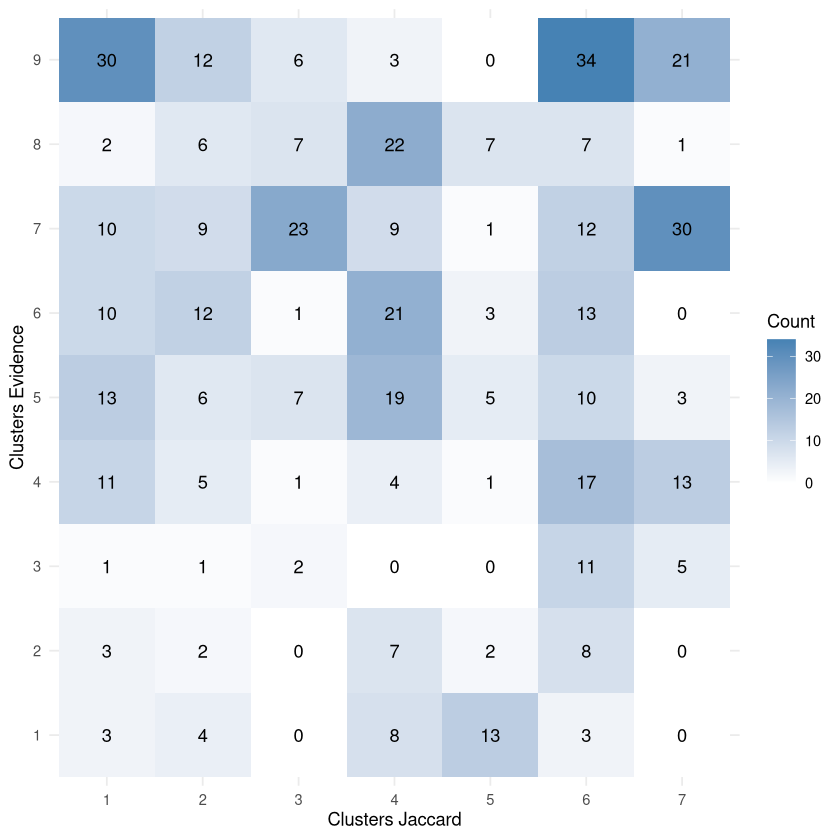

In [4]:
conf_mat <- table(evidence_clusters$Clusters_heatmap, jaccard_clusters$Clusters_heatmap)
conf_df <- as.data.frame(conf_mat)

# png(filename = "../../Results/Plots/clusters_confusion_matrix.png"), width = 2200, height = 2000, res = 400)
ggplot(conf_df, aes(Var2, Var1, fill = Freq)) +
  geom_tile() +
  geom_text(aes(label = Freq)) +
  scale_fill_gradient(low = "white", high = "steelblue") +
  labs(x = "Clusters Jaccard",
       y = "Clusters Evidence",
       fill = "Count") +
  theme_minimal()

# dev.off()

In [5]:
ARI(jaccard_clusters$Clusters_heatmap, evidence_clusters$Clusters_heatmap)

[1] 0.06161297